# Dự báo tải sưởi của tòa nhà (Energy Efficiency, UCI): pipeline hồi quy với tiền xử lý và PCA
Môn Nhận dạng mẫu, PTIT (TS. Nguyễn Xuân Đức). Bài tập cá nhân.

Bài toán: từ 8 thông số thiết kế của tòa nhà (độ nhỏ gọn, diện tích bề mặt, tường, mái, chiều cao, hướng, diện tích kính và cách phân bố kính), dự báo tải sưởi Heating Load (kWh/m²).

Dữ liệu: Energy Efficiency (Tsanas & Xifara, 2012; UCI #242), 768 tòa nhà mô phỏng bằng Ecotect. Bài này chỉ dùng target Y1 (tải sưởi).

Nội dung notebook:
1. Đọc dữ liệu và kiểm tra cấu trúc
2. Chia Dev/Test và thiết lập CV
3. So sánh hai cách biểu diễn X6, X8 (số và one-hot), xây dựng pipeline
4. Phân tích PCA trên dữ liệu Dev
5. So sánh baseline và các mô hình hồi quy, mỗi mô hình chạy có và không có PCA
6. Quét số thành phần k của PCA
7. Kiểm tra dự báo cho hình dạng tòa nhà chưa có trong dữ liệu train
8. Chọn mô hình bằng quy tắc 1-SE, đánh giá trên Test
9. Phân tích lỗi của mô hình được chọn

Tất cả kết quả được lưu vào thư mục `results/` (CSV) và `figs/` (hình). Seed cố định là 42.

In [1]:
import time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, GroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
FIG, RES = Path("figs"), Path("results"); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
C_BASE, C_NO, C_PCA = "#9aa0a6", "#2b6cb0", "#dd6b20"
t0_all = time.time()

## 1. Dữ liệu
| Ký hiệu | Tên | Ý nghĩa | Số mức |
|---|---|---|---|
| X1 | Relative Compactness | Độ nhỏ gọn của khối nhà | 12 |
| X2 | Surface Area (m²) | Tổng diện tích bề mặt | 12 |
| X3 | Wall Area (m²) | Diện tích tường | 7 |
| X4 | Roof Area (m²) | Diện tích mái | 4 |
| X5 | Overall Height (m) | Chiều cao: 3,5 (1 tầng) hoặc 7 (2 tầng) | 2 |
| X6 | Orientation | Hướng: 2 = Bắc, 3 = Đông, 4 = Nam, 5 = Tây | 4 |
| X7 | Glazing Area | Diện tích kính so với diện tích sàn: 0, 10, 25, 40 % | 4 |
| X8 | Glazing Area Distribution | Phân bố kính: 0 = không kính, 1 = đều 4 mặt, 2–5 = dồn nhiều về Bắc/Đông/Nam/Tây | 6 |
| Y1 | Heating Load (kWh/m²) | Tải sưởi, là target | liên tục |

File `energy_efficiency_Y1.csv` là bản sao dữ liệu UCI trong kho `yaringal/DropoutUncertaintyExps` (Gal & Ghahramani), chỉ có cột Y1. Cell dưới đọc dữ liệu, in kích thước, số giá trị thiếu, số dòng trùng và số mức của từng đặc trưng.

In [2]:
TARGET = "Y1"
FEATS = ["X1", "X2", "X3", "X4", "X5", "X6", "X7", "X8"]
df = pd.read_csv("energy_efficiency_Y1.csv")
X = df[FEATS]; y = df[TARGET]
print("Kích thước:", df.shape, "| thiếu:", int(df.isna().sum().sum()), "| trùng X:", int(X.duplicated().sum()))
print(y.describe().round(2))
print("Số mức của từng đặc trưng:", X.nunique().to_dict())

Kích thước: (768, 9) | thiếu: 0 | trùng X: 0
count    768.00
mean      22.31
std       10.09
min        6.01
25%       12.99
50%       18.95
75%       31.67
max       43.10
Name: Y1, dtype: float64
Số mức của từng đặc trưng: {'X1': 12, 'X2': 12, 'X3': 7, 'X4': 4, 'X5': 2, 'X6': 4, 'X7': 4, 'X8': 6}


### Cấu trúc thiết kế thí nghiệm
Dữ liệu được sinh theo thiết kế thí nghiệm: 768 = 12 hình dạng × 4 hướng × 16 cấu hình kính (1 không kính + 3 mức diện tích × 5 cách phân bố). Cell dưới kiểm tra:
- mỗi giá trị X1 ứng với một hình dạng, mỗi hình dạng có 64 mẫu;
- X2 = X3 + 2·X4 với mọi mẫu (bề mặt = tường + mái + sàn, diện tích sàn bằng diện tích mái);
- mỗi hình dạng chỉ có một bộ giá trị X2..X5, và ma trận X1..X5 có hạng 4, tức là có đa cộng tuyến hoàn hảo.

In [3]:
shape_id = X["X1"].rank(method="dense").astype(int)
print("Số hình dạng:", shape_id.nunique(), "| mỗi hình dạng có", shape_id.value_counts().unique(), "mẫu")
print("X2 == X3 + 2*X4 với mọi mẫu:", bool(np.allclose(X.X2, X.X3 + 2 * X.X4)))
print("Mỗi hình dạng có đúng 1 giá trị X2..X5:", bool((df.groupby(shape_id)[["X2", "X3", "X4", "X5"]].nunique() == 1).all().all()))
print("Hạng ma trận X1..X5:", np.linalg.matrix_rank(X[["X1", "X2", "X3", "X4", "X5"]].values), "/ 5")
print(df.groupby("X5")[TARGET].describe().round(2))
print(df.groupby("X7")[TARGET].mean().round(2))
print(df.groupby("X6")[TARGET].mean().round(2))

Số hình dạng: 12 | mỗi hình dạng có [64] mẫu
X2 == X3 + 2*X4 với mọi mẫu: True
Mỗi hình dạng có đúng 1 giá trị X2..X5: True
Hạng ma trận X1..X5: 4 / 5
     count   mean   std    min    25%    50%    75%    max
X5                                                        
3.5  384.0  13.34  2.67   6.01  11.58  12.98  15.09  19.52
7.0  384.0  31.28  5.95  15.55  27.01  31.68  36.00  43.10
X7
0.00    14.29
0.10    20.36
0.25    22.76
0.40    25.41
Name: Y1, dtype: float64
X6
2    22.31
3    22.38
4    22.26
5    22.28
Name: Y1, dtype: float64


Vẽ phân phối target (tách theo chiều cao X5 và theo diện tích kính X7) và ma trận tương quan Pearson giữa các đặc trưng và target.

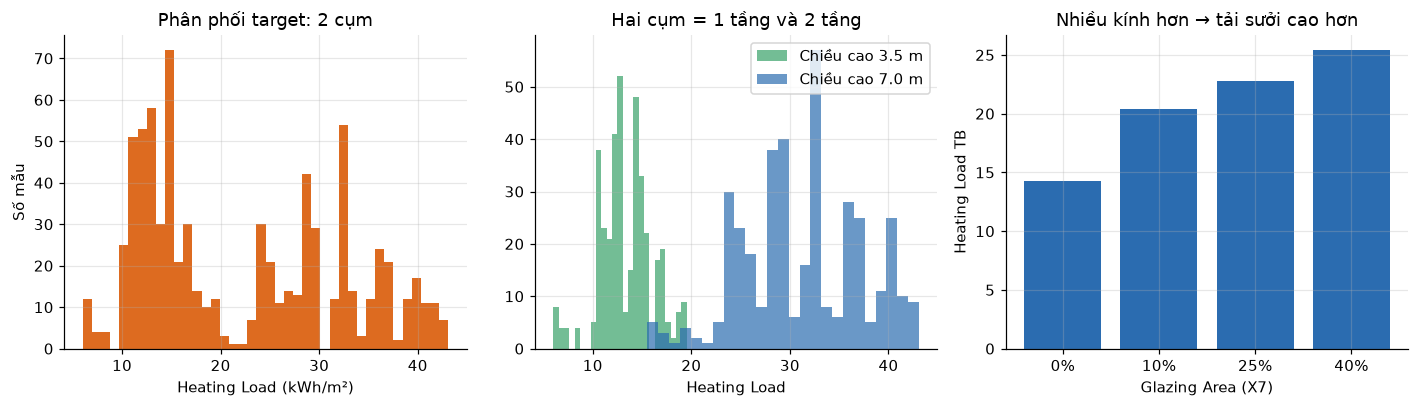

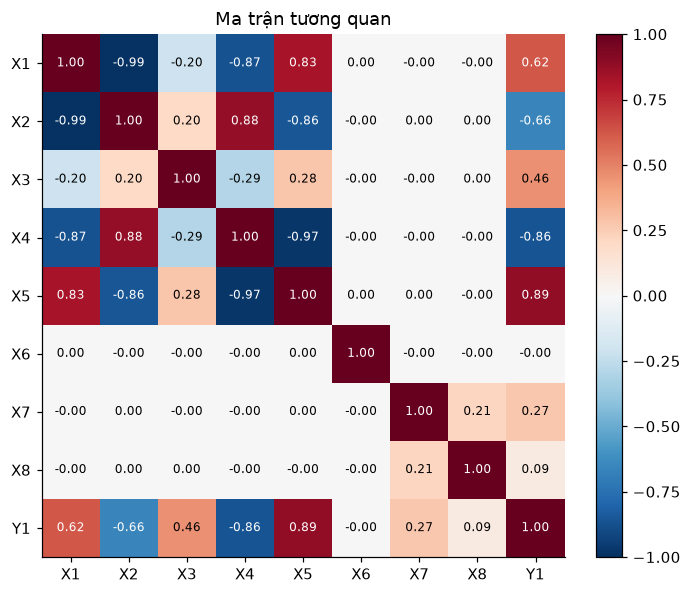

      X1    X2    X3    X4    X5   X6    X7    X8    Y1
X1  1.00 -0.99 -0.20 -0.87  0.83  0.0 -0.00 -0.00  0.62
X2 -0.99  1.00  0.20  0.88 -0.86 -0.0  0.00  0.00 -0.66
X3 -0.20  0.20  1.00 -0.29  0.28 -0.0 -0.00  0.00  0.46
X4 -0.87  0.88 -0.29  1.00 -0.97 -0.0 -0.00 -0.00 -0.86
X5  0.83 -0.86  0.28 -0.97  1.00  0.0  0.00 -0.00  0.89
X6  0.00 -0.00 -0.00 -0.00  0.00  1.0 -0.00 -0.00 -0.00
X7 -0.00  0.00 -0.00 -0.00  0.00 -0.0  1.00  0.21  0.27
X8 -0.00  0.00  0.00 -0.00 -0.00 -0.0  0.21  1.00  0.09
Y1  0.62 -0.66  0.46 -0.86  0.89 -0.0  0.27  0.09  1.00


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(y, bins=40, color=C_PCA); axes[0].set_xlabel("Heating Load (kWh/m²)"); axes[0].set_ylabel("Số mẫu")
axes[0].set_title("Phân phối target: 2 cụm")
for h, c in [(3.5, "#38a169"), (7.0, C_NO)]:
    axes[1].hist(y[X.X5 == h], bins=25, alpha=.7, color=c, label=f"Chiều cao {h} m")
axes[1].legend(); axes[1].set_xlabel("Heating Load"); axes[1].set_title("Hai cụm = 1 tầng và 2 tầng")
g = df.groupby("X7")[TARGET].mean()
axes[2].bar([f"{int(v*100)}%" for v in g.index], g.values, color=C_NO); axes[2].set_xlabel("Glazing Area (X7)")
axes[2].set_ylabel("Heating Load TB"); axes[2].set_title("Nhiều kính hơn → tải sưởi cao hơn")
fig.tight_layout(); fig.savefig(FIG / "01_target.png"); plt.show()

corr = df[FEATS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(9)); ax.set_xticklabels(corr.columns); ax.set_yticks(range(9)); ax.set_yticklabels(corr.columns)
for i in range(9):
    for j in range(9):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(corr.iloc[i, j]) > .6 else "black")
fig.colorbar(im, fraction=.046); ax.set_title("Ma trận tương quan"); fig.tight_layout(); fig.savefig(FIG / "02_corr.png"); plt.show()
corr.round(3).to_csv(RES / "corr.csv"); print(corr.round(2))

## 2. Chia dữ liệu
Chia Dev 80 % / Test 20 %, phân tầng theo X5 để hai tập có cùng tỉ lệ nhà 1 tầng và 2 tầng. Từ đây đến phần 8 chỉ dùng tập Dev.

Hai cách chia CV trên Dev:
- `cv_tune`: KFold 5, dùng để chọn siêu tham số và cho các so sánh nhanh ở phần 3, 6, 7;
- `cv_stab`: RepeatedKFold 5 × 5 = 25 fold, dùng để đo trung bình và độ lệch chuẩn của lỗi ở phần 5.

In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=X["X5"])
print("Dev:", X_dev.shape, "Test:", X_test.shape)
cv_tune = KFold(5, shuffle=True, random_state=SEED)
cv_stab = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)

Dev: (614, 8) Test: (154, 8)


## 3. Biểu diễn và tiền xử lý
X6 (hướng) và X8 (phân bố kính) là biến định danh: các số 2, 3, 4, 5 chỉ là nhãn. So sánh hai cách biểu diễn bằng CV (KFold 5) trên 4 mô hình đại diện:
- numeric: giữ nguyên 8 cột, chuẩn hoá tất cả;
- onehot: X6 thành 4 cột, X8 thành 6 cột, 6 cột số còn lại chuẩn hoá (tổng 16 cột), sau đó chuẩn hoá lại toàn bộ.

Hàm `make_pipe` ghép các bước: tiền xử lý → (PCA) → (đa thức bậc 2 + chuẩn hoá) → mô hình. Vì mọi bước nằm trong `Pipeline`, khi chạy CV các tham số chuẩn hoá và PCA chỉ được học trên phần train của từng fold. Biểu diễn có RMSE trung bình thấp hơn được dùng cho các phần sau.

In [6]:
NUM = ["X1", "X2", "X3", "X4", "X5", "X7"]; CAT = ["X6", "X8"]
def make_pre(enc):
    if enc == "numeric":
        return ColumnTransformer([("num", StandardScaler(), FEATS)])
    return ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def make_pipe(model, pca=False, poly=False, enc="onehot"):
    steps = [("pre", make_pre(enc))]
    if enc == "onehot": steps.append(("scale_all", StandardScaler()))
    if pca: steps.append(("pca", PCA(random_state=SEED)))
    if poly: steps += [("poly", PolynomialFeatures(2, include_bias=False)), ("scale2", StandardScaler())]
    steps.append(("model", model))
    return Pipeline(steps)

def cv_score(pipe, cv=cv_tune, groups=None):
    s = cross_validate(pipe, X_dev, y_dev, cv=cv, groups=groups, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -s["test_score"].mean(), s["test_score"].std(ddof=1)

HGB = lambda: HistGradientBoostingRegressor(random_state=SEED, max_iter=500, learning_rate=0.1, max_leaf_nodes=15, min_samples_leaf=5)
enc_rows = []
for enc in ["numeric", "onehot"]:
    for nm, mdl in [("Ridge", Ridge(1.0)), ("Poly2 + Ridge", None), ("KNN", KNeighborsRegressor(5, weights="distance")), ("HistGB", HGB())]:
        p = make_pipe(Ridge(1.0), poly=True, enc=enc) if mdl is None else make_pipe(mdl, enc=enc)
        m, s = cv_score(p); enc_rows.append({"biểu diễn": enc, "model": nm, "CV_RMSE": m, "std": s})
enc_df = pd.DataFrame(enc_rows); enc_df.to_csv(RES / "encoding_compare.csv", index=False)
print(enc_df.pivot(index="model", columns="biểu diễn", values="CV_RMSE").round(3))
ENC = enc_df.groupby("biểu diễn").CV_RMSE.mean().idxmin(); print("==> Chốt biểu diễn:", ENC)

biểu diễn      numeric  onehot
model                         
HistGB           0.412   0.413
KNN              2.421   3.899
Poly2 + Ridge    2.233   2.299
Ridge            3.090   2.990
==> Chốt biểu diễn: numeric


## 4. Phân tích PCA
Phần này chỉ để khám phá cấu trúc: chuẩn hoá toàn bộ Dev rồi fit PCA đầy đủ. Khi so sánh mô hình ở phần 5, PCA được fit lại bên trong từng fold.

Cell dưới in ra:
- tỉ lệ phương sai giải thích (EVR) của từng PC, số PC cần giữ để đạt 80/90/95/99 % phương sai, và vẽ scree plot;
- kết quả PCA riêng trên 5 đặc trưng hình học X1..X5;
- loadings của 3 PC đầu, và |tương quan| giữa từng PC với tải sưởi;
- hình chiếu dữ liệu lên PC1–PC2, tô màu theo tải sưởi.

d = 8 | số PC cần giữ 80/90/95/99 %: {0.8: 4, 0.9: 5, 0.95: 5, 0.99: 5}
EVR: [46.399 15.679 15.326 12.501  9.361  0.681  0.053  0.   ]
Số PC có phương sai ≈ 0: 1


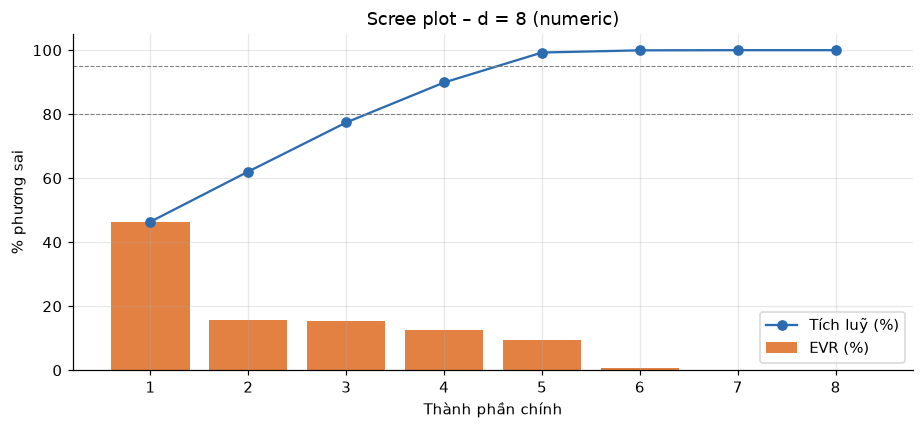

PCA trên X1..X5 – EVR (%): [74.225 24.6    1.091  0.085  0.   ]
      PC1    PC2
X1 -0.496 -0.239
X2  0.502  0.228
X3 -0.031  0.898
X4  0.505 -0.202
X5 -0.496  0.209
           PC1    PC2    PC3
num__X1 -0.496  0.089 -0.222
num__X2  0.502 -0.084  0.212
num__X3 -0.031 -0.340  0.831
num__X4  0.505  0.078 -0.186
num__X5 -0.496 -0.082  0.192
num__X6 -0.007 -0.088 -0.029
num__X7 -0.013  0.644  0.278
num__X8  0.005  0.659  0.257
 PC   EVR_%  abs_corr_y
  1 46.3993      0.7947
  2 15.6788      0.0559
  3 15.3259      0.4729
  4 12.5011      0.0221
  5  9.3607      0.1274
  6  0.6812      0.1826
  7  0.0530      0.0358
  8  0.0000      0.0000


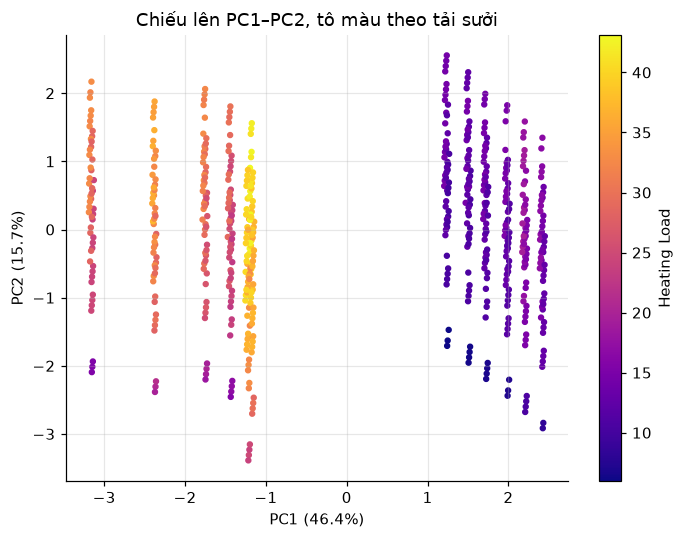

In [7]:
pre_fit = Pipeline(make_pipe(LinearRegression(), enc=ENC).steps[:-1]).fit(X_dev)
Z = pre_fit.transform(X_dev); D = Z.shape[1]
pca_full = PCA().fit(Z); evr = pca_full.explained_variance_ratio_; cum = evr.cumsum()
K = {t: int(np.argmax(cum >= t - 1e-12) + 1) for t in (0.80, 0.90, 0.95, 0.99)}
print(f"d = {D} | số PC cần giữ 80/90/95/99 %:", K)
print("EVR:", np.round(evr * 100, 3))
n_zero = int((evr < 1e-6).sum()); print("Số PC có phương sai ≈ 0:", n_zero)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(range(1, D + 1), evr * 100, color=C_PCA, alpha=.85, label="EVR (%)")
ax.plot(range(1, D + 1), cum * 100, "o-", color=C_NO, label="Tích luỹ (%)")
for t in (80, 95): ax.axhline(t, ls="--", lw=.7, color="grey")
ax.set_xticks(range(1, D + 1)); ax.set_xlabel("Thành phần chính"); ax.set_ylabel("% phương sai"); ax.legend()
ax.set_title(f"Scree plot – d = {D} ({ENC})"); fig.tight_layout(); fig.savefig(FIG / "03_scree.png"); plt.show()
pd.DataFrame({"PC": range(1, D + 1), "EVR": evr, "cum": cum}).to_csv(RES / "pca_evr.csv", index=False)

Zg = StandardScaler().fit_transform(X_dev[["X1", "X2", "X3", "X4", "X5"]])
pg = PCA().fit(Zg); print("PCA trên X1..X5 – EVR (%):", np.round(pg.explained_variance_ratio_ * 100, 3))
geo = pd.DataFrame(pg.components_[:2].T, index=["X1", "X2", "X3", "X4", "X5"], columns=["PC1", "PC2"]).round(3)
geo.to_csv(RES / "pca_geometry_loadings.csv"); print(geo)
json.dump({"geo_evr": pg.explained_variance_ratio_.tolist()}, open(RES / "pca_geometry.json", "w"))

names_out = pre_fit.named_steps["pre"].get_feature_names_out()
load = pd.DataFrame(pca_full.components_[:3].T, index=names_out, columns=["PC1", "PC2", "PC3"]).round(3)
load.to_csv(RES / "pca_loadings.csv"); print(load)
S = pca_full.transform(Z)
pc_y = pd.DataFrame({"PC": range(1, D + 1), "EVR_%": evr * 100,
                     "abs_corr_y": [abs(np.corrcoef(S[:, j], y_dev)[0, 1]) if S[:, j].std() > 1e-9 else 0 for j in range(D)]}).round(4)
pc_y.to_csv(RES / "pc_target_corr.csv", index=False); print(pc_y.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 5))
sc_ = ax.scatter(S[:, 0], S[:, 1], c=y_dev, s=10, cmap="plasma")
fig.colorbar(sc_, label="Heating Load"); ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title("Chiếu lên PC1–PC2, tô màu theo tải sưởi"); fig.tight_layout(); fig.savefig(FIG / "04_pc12.png"); plt.show()

## 5. Baseline và các mô hình hồi quy, có và không có PCA
Các mô hình: 2 baseline (đoán hằng số bằng mean/median), Linear, Ridge, Lasso, Poly(2) + Ridge, KNN, Random Forest, HistGradientBoosting. Mỗi mô hình (trừ baseline) chạy hai biến thể: không PCA và có PCA.

Với mỗi biến thể, GridSearchCV (KFold 5, tối ưu RMSE) chọn siêu tham số; ở biến thể có PCA, số thành phần k ∈ {1, 2, 3, 4, 5, 6, 8} cũng nằm trong lưới. Cấu hình tốt nhất sau đó được đánh giá lại trên 25 fold để lấy trung bình, độ lệch chuẩn và sai số chuẩn (SE) của RMSE, cùng MAE, R² và RMSE trên tập train.

Lưu ý: PC8 có phương sai bằng 0 (do X2 = X3 + 2·X4), nên khi k = 8 thành phần này chỉ chứa sai số làm tròn. Với các mô hình tuyến tính và KNN điều này gần như không ảnh hưởng, nhưng HistGB + PCA có thể chọn k khác nhau (6 hoặc 8) khi chạy trên máy hoặc phiên bản thư viện khác, RMSE lệch khoảng 0,01.

In [8]:
K_GRID = [1, 2, 3, 4, 5, 6, 8]
MODELS = {
    "Baseline (mean)":   (DummyRegressor(strategy="mean"), {}, False),
    "Baseline (median)": (DummyRegressor(strategy="median"), {}, False),
    "Linear":            (LinearRegression(), {}, False),
    "Ridge":             (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10]}, False),
    "Lasso":             (Lasso(max_iter=20000), {"model__alpha": [0.001, 0.01, 0.1]}, False),
    "Poly2 + Ridge":     (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10]}, True),
    "KNN":               (KNeighborsRegressor(weights="distance"), {"model__n_neighbors": [3, 5, 10]}, False),
    "RandomForest":      (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1), {"model__min_samples_leaf": [1, 3]}, False),
    "HistGB":            (HistGradientBoostingRegressor(random_state=SEED, max_iter=500, min_samples_leaf=5),
                          {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [7, 15]}, False),
}
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
rows, best, folds = [], {}, {}
for name, (model, grid, poly) in MODELS.items():
    for use_pca in ([False] if name.startswith("Baseline") else [False, True]):
        label = name + (" + PCA" if use_pca else "")
        g = dict(grid)
        if use_pca: g["pca__n_components"] = K_GRID
        pipe = make_pipe(model, pca=use_pca, poly=poly, enc=ENC); t0 = time.time(); params = {}
        if g:
            gs = GridSearchCV(pipe, g, cv=cv_tune, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_dev, y_dev)
            pipe, params = gs.best_estimator_, gs.best_params_
        r = cross_validate(pipe, X_dev, y_dev, cv=cv_stab, scoring=SCORING, return_train_score=True, n_jobs=-1)
        rm = -r["test_rmse"]; folds[label] = rm; best[label] = pipe
        rows.append({"model": label, "family": name, "pca": use_pca,
                     "params": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in params.items()),
                     "CV_RMSE": rm.mean(), "CV_RMSE_std": rm.std(ddof=1), "CV_RMSE_SE": rm.std(ddof=1) / np.sqrt(len(rm)),
                     "CV_MAE": -r["test_mae"].mean(), "CV_MAE_std": r["test_mae"].std(ddof=1),
                     "CV_R2": r["test_r2"].mean(), "CV_R2_std": r["test_r2"].std(ddof=1),
                     "Train_RMSE": -r["train_rmse"].mean(), "time_s": time.time() - t0})
        print(f"{label:24s} RMSE={rm.mean():6.3f}±{rm.std(ddof=1):5.3f} MAE={-r['test_mae'].mean():.3f} R2={r['test_r2'].mean():.4f} {rows[-1]['params']}", flush=True)
res = pd.DataFrame(rows); res.to_csv(RES / "cv_results.csv", index=False)

Baseline (mean)          RMSE=10.136±0.426 MAE=9.166 R2=-0.0118 


Baseline (median)        RMSE=10.710±0.703 MAE=9.090 R2=-0.1299 


Linear                   RMSE= 3.074±0.259 MAE=2.197 R2=0.9065 


Linear + PCA             RMSE= 3.074±0.259 MAE=2.197 R2=0.9065 n_components=8


Ridge                    RMSE= 3.074±0.259 MAE=2.197 R2=0.9065 alpha=0.1


...

KNN + PCA                RMSE= 1.620±0.387 MAE=1.234 R2=0.9729 n_neighbors=3, n_components=3


RandomForest             RMSE= 0.530±0.061 MAE=0.360 R2=0.9972 min_samples_leaf=1


RandomForest + PCA       RMSE= 0.940±0.183 MAE=0.641 R2=0.9910 min_samples_leaf=1, n_components=8


HistGB                   RMSE= 0.397±0.054 MAE=0.267 R2=0.9984 learning_rate=0.1, max_leaf_nodes=15


HistGB + PCA             RMSE= 0.962±0.205 MAE=0.630 R2=0.9905 learning_rate=0.05, max_leaf_nodes=7, n_components=8


Hai hình dưới: RMSE trung bình qua 25 fold của từng mô hình (thanh lỗi là độ lệch chuẩn), và boxplot RMSE theo fold để xem độ ổn định. Cả hai dùng thang log vì baseline lớn hơn các mô hình khác hàng chục lần.

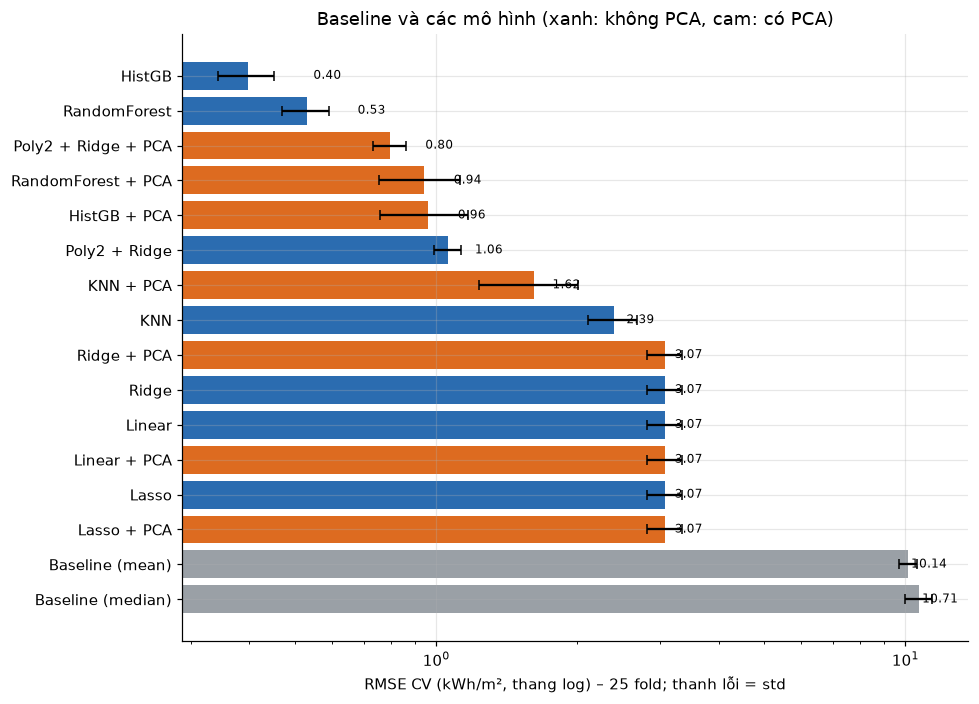

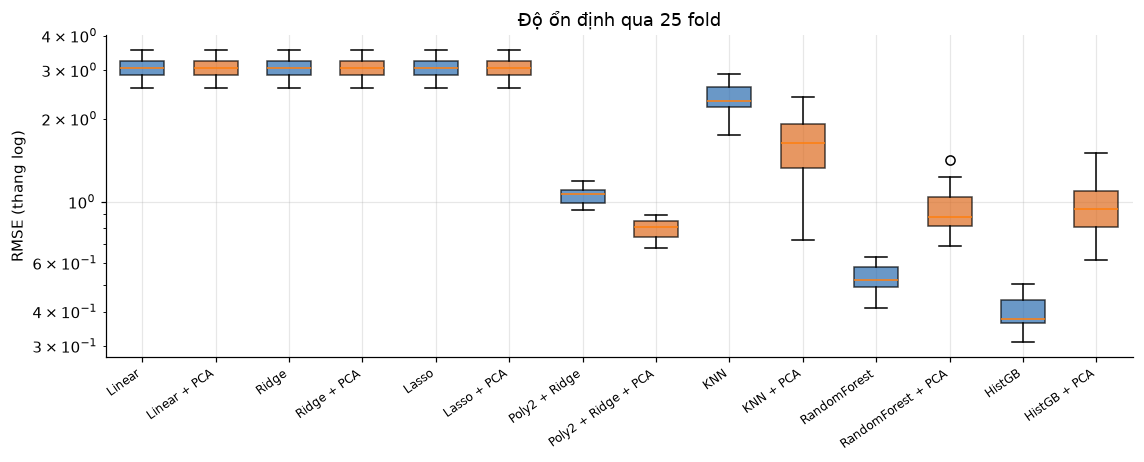

In [9]:
order = res.sort_values("CV_RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.5))
cols = [C_BASE if m.startswith("Baseline") else (C_PCA if p else C_NO) for m, p in zip(order.model, order.pca)]
ax.barh(order.model, order.CV_RMSE, xerr=order.CV_RMSE_std, color=cols, capsize=3)
for i, v in enumerate(order.CV_RMSE): ax.text(v + .15, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("RMSE CV (kWh/m², thang log) – 25 fold; thanh lỗi = std")
ax.set_title("Baseline và các mô hình (xanh: không PCA, cam: có PCA)"); fig.tight_layout(); fig.savefig(FIG / "05_cv_bar.png"); plt.show()
nb = [m for m in res.model if not m.startswith("Baseline")]
fig, ax = plt.subplots(figsize=(10.5, 4.3))
bp = ax.boxplot([folds[m] for m in nb], patch_artist=True, widths=.6)
for b_, m in zip(bp["boxes"], nb): b_.set_facecolor(C_PCA if "PCA" in m else C_NO); b_.set_alpha(.7)
ax.set_xticks(range(1, len(nb) + 1)); ax.set_xticklabels(nb, rotation=35, ha="right", fontsize=8)
ax.set_yscale("log"); ax.set_ylabel("RMSE (thang log)"); ax.set_title("Độ ổn định qua 25 fold")
fig.tight_layout(); fig.savefig(FIG / "06_cv_box.png"); plt.show()

## 6. Tác động của PCA theo số thành phần k
Lấy siêu tham số tốt nhất (bản không PCA) của Ridge, Poly(2) + Ridge, KNN và HistGB ở phần 5, thêm PCA với k chạy từ 1 đến 8 và đo RMSE bằng KFold 5. Trên hình, nét chấm là RMSE 25 fold của cùng mô hình khi không dùng PCA, đường dọc là số PC giữ 95 % phương sai.

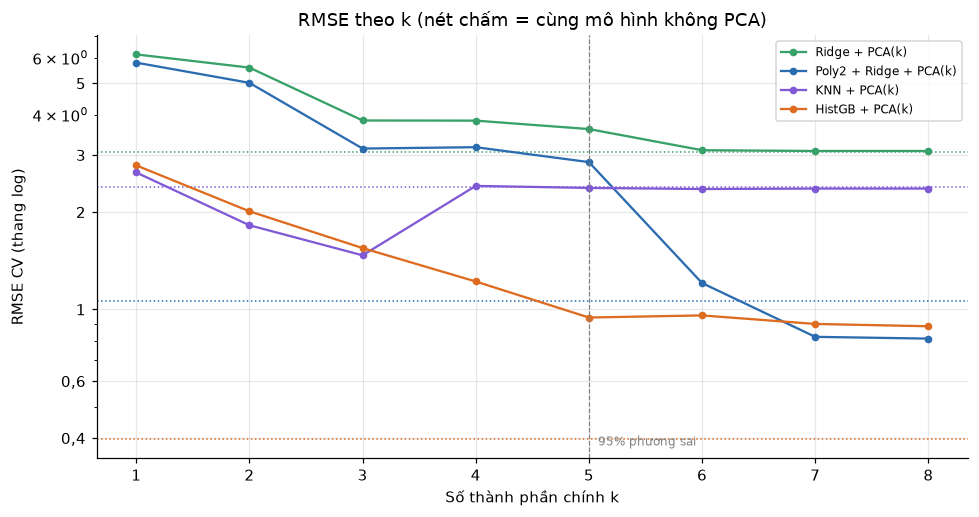

model  HistGB    KNN  Poly2 + Ridge  Ridge
k                                         
1       2.787  2.651          5.794  6.144
2       2.011  1.820          5.017  5.592
3       1.547  1.470          3.143  3.838
4       1.220  2.409          3.173  3.834
5       0.944  2.375          2.854  3.611
6       0.958  2.356          1.206  3.106
7       0.902  2.364          0.823  3.089
8       0.887  2.364          0.812  3.089


In [10]:
curve = []
for name in ["Ridge", "Poly2 + Ridge", "KNN", "HistGB"]:
    mdl = best[name].named_steps["model"]
    for k in range(1, D + 1):
        p = make_pipe(mdl, pca=True, poly=(name == "Poly2 + Ridge"), enc=ENC); p.set_params(pca__n_components=k)
        m, s = cv_score(p); curve.append({"model": name, "k": k, "RMSE": m, "std": s})
curve = pd.DataFrame(curve); curve.to_csv(RES / "pca_k_curve.csv", index=False)
pal = {"Ridge": "#38a169", "Poly2 + Ridge": "#2b6cb0", "KNN": "#805ad5", "HistGB": C_PCA}
fig, ax = plt.subplots(figsize=(9, 4.8))
for n in pal:
    c = curve[curve.model == n]; ax.plot(c.k, c.RMSE, "o-", ms=4, color=pal[n], label=f"{n} + PCA(k)")
    ax.axhline(res.loc[res.model == n, "CV_RMSE"].iloc[0], ls=":", color=pal[n], lw=1)
ax.axvline(K[0.95], ls="--", color="grey", lw=.8); ax.text(K[0.95] + .08, 0.03, "95% phương sai", fontsize=8, color="grey", transform=ax.get_xaxis_transform())
ax.set_yscale("log"); ax.set_yticks([0.4, 0.6, 1, 2, 3, 5]); ax.set_yticklabels(["0,4", "0,6", "1", "2", "3", "5"]); ax.set_xticks(range(1, D + 1)); ax.set_xlabel("Số thành phần chính k"); ax.set_ylabel("RMSE CV (thang log)")
ax.set_title("RMSE theo k (nét chấm = cùng mô hình không PCA)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "07_pca_k.png"); plt.show()
print(curve.pivot(index="k", columns="model", values="RMSE").round(3))

In đủ loadings của 8 PC để xem mỗi PC ứng với đặc trưng nào, đặc biệt là PC chứa hướng nhà X6, và in tương quan giữa X6 với tải sưởi.

In [11]:
load_all = pd.DataFrame(pca_full.components_.T, index=FEATS, columns=[f"PC{i}" for i in range(1, D + 1)]).round(2)
load_all.to_csv(RES / "pca_loadings_all.csv"); print(load_all)
print("|corr(X6, y)| =", round(abs(np.corrcoef(X_dev.X6, y_dev)[0, 1]), 4))

     PC1   PC2   PC3   PC4   PC5   PC6   PC7   PC8
X1 -0.50  0.09 -0.22 -0.00 -0.00 -0.50  0.67  0.00
X2  0.50 -0.08  0.21  0.00 -0.00  0.07  0.50 -0.66
X3 -0.03 -0.34  0.83 -0.01  0.01 -0.29  0.08  0.32
X4  0.51  0.08 -0.19  0.01 -0.01  0.20  0.45  0.68
X5 -0.50 -0.08  0.19 -0.01  0.02  0.79  0.29  0.00
X6 -0.01 -0.09 -0.03  0.99  0.10 -0.00  0.00  0.00
X7 -0.01  0.64  0.28  0.13 -0.70  0.01  0.00  0.00
X8  0.00  0.66  0.26 -0.00  0.71 -0.00 -0.00 -0.00
|corr(X6, y)| = 0.0014


## 7. Dự báo cho hình dạng tòa nhà chưa thấy
KFold ngẫu nhiên chỉ kiểm tra khả năng dự báo biến thể mới (hướng, cách bố trí kính) của các hình dạng đã có trong train. Để kiểm tra với hình dạng hoàn toàn mới, dùng GroupKFold(6) với nhóm là hình dạng (12 hình dạng, mỗi fold giữ lại 2 hình dạng làm tập kiểm tra). So sánh với KFold 5 ngẫu nhiên trên cùng các mô hình.

In [12]:
g_dev = X_dev["X1"].rank(method="dense").astype(int)
cv_shape = GroupKFold(n_splits=6)
shape_rows = []
for m in ["Ridge", "Poly2 + Ridge", "KNN", "RandomForest", "HistGB", "HistGB + PCA"]:
    a, _ = cv_score(best[m]); b, _ = cv_score(best[m], cv=cv_shape, groups=g_dev)
    shape_rows.append({"model": m, "KFold ngẫu nhiên": a, "GroupKFold theo hình dạng": b})
shape_df = pd.DataFrame(shape_rows); shape_df.to_csv(RES / "shape_generalization.csv", index=False); print(shape_df.round(3))

           model  KFold ngẫu nhiên  GroupKFold theo hình dạng
0          Ridge             3.089                      3.848
1  Poly2 + Ridge             1.077                     13.267
2            KNN             2.365                      4.672
3   RandomForest             0.533                      6.524
4         HistGB             0.412                      8.556
5   HistGB + PCA             0.869                      6.440


## 8. Chọn mô hình và đánh giá trên Test
Quy tắc 1-SE: lấy mô hình có RMSE CV thấp nhất, ngưỡng = RMSE của nó + SE. Trong các mô hình có RMSE dưới ngưỡng, chọn mô hình có độ lệch chuẩn nhỏ nhất. Sau khi đã chốt, refit mọi mô hình trên toàn bộ Dev và tính MAE, RMSE, R² trên Test, kèm mức giảm RMSE so với baseline (mean). Kết quả Test của các mô hình khác chỉ để tham khảo, không dùng để chọn.

In [13]:
cand = res[~res.model.str.startswith("Baseline")].sort_values("CV_RMSE")
top = cand.iloc[0]; thr = top.CV_RMSE + top.CV_RMSE_SE
within = cand[cand.CV_RMSE <= thr]; chosen = within.sort_values(["CV_RMSE_std", "CV_RMSE"]).iloc[0]["model"]
print(f"Tốt nhất: {top.model} {top.CV_RMSE:.3f} (SE {top.CV_RMSE_SE:.3f}) → ngưỡng {thr:.3f}; trong ngưỡng: {list(within.model)} → chọn {chosen}")
test_rows, preds = [], {}
for m in res.model:
    p = best[m].fit(X_dev, y_dev); yp = p.predict(X_test); preds[m] = yp
    test_rows.append({"model": m, "Test_MAE": mean_absolute_error(y_test, yp), "Test_RMSE": root_mean_squared_error(y_test, yp), "Test_R2": r2_score(y_test, yp)})
test = pd.DataFrame(test_rows).merge(res[["model", "CV_RMSE", "CV_RMSE_std"]], on="model")
b = test.loc[test.model == "Baseline (mean)", "Test_RMSE"].iloc[0]; test["giam_vs_baseline_%"] = (1 - test.Test_RMSE / b) * 100
test.to_csv(RES / "test_results.csv", index=False); print(test.round(4).to_string())

Tốt nhất: HistGB 0.397 (SE 0.011) → ngưỡng 0.408; trong ngưỡng: ['HistGB'] → chọn HistGB


                  model  Test_MAE  Test_RMSE  Test_R2  CV_RMSE  CV_RMSE_std  giam_vs_baseline_%
0       Baseline (mean)    9.1031     9.9260  -0.0016  10.1361       0.4260              0.0000
1     Baseline (median)    9.0436    10.5489  -0.1312  10.7098       0.7034             -6.2755
2                Linear    1.7639     2.3725   0.9428   3.0744       0.2590             76.0982
3          Linear + PCA    1.7639     2.3725   0.9428   3.0744       0.2590             76.0982
4                 Ridge    1.7629     2.3732   0.9427   3.0743       0.2593             76.0907
5           Ridge + PCA    1.7629     2.3732   0.9427   3.0743       0.2593             76.0907
6                 Lasso    1.7627     2.3732   0.9427   3.0744       0.2592             76.0908
7           Lasso + PCA    1.7628     2.3734   0.9427   3.0745       0.2592             76.0893
8         Poly2 + Ridge    0.7668     0.9570   0.9907   1.0596       0.0696             90.3588
9   Poly2 + Ridge + PCA    0.5470     0.

## 9. Phân tích lỗi của mô hình được chọn
Trên tập Test: vẽ giá trị thực tế so với dự báo và phần dư theo giá trị dự báo; tính MAE theo chiều cao (X5), diện tích kính (X7), hướng (X6); liệt kê 8 mẫu có sai số tuyệt đối lớn nhất.

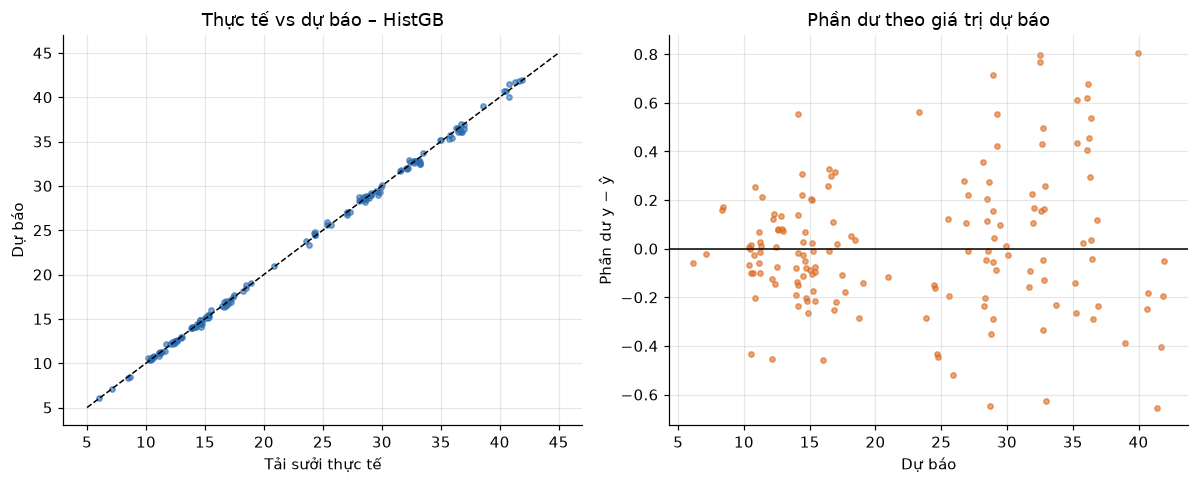

Chiều cao 
       n    MAE
X5            
3.5  77  0.136
7.0  77  0.289
Diện tích kính 
        n    MAE
X7             
0.00   6  0.164
0.10  50  0.228
0.25  47  0.189
0.40  51  0.225
Hướng 
      n    MAE
X6           
2   34  0.225
3   50  0.195
4   31  0.159
5   39  0.267
       X1     X2     X3     X4   X5  X6    X7  X8      y    pred     ae
548  0.76  661.5  416.5  122.5  7.0   2  0.40   1  40.78  39.975  0.805
165  0.76  661.5  416.5  122.5  7.0   3  0.10   3  33.28  32.483  0.797
263  0.76  661.5  416.5  122.5  7.0   5  0.10   5  33.27  32.504  0.766
637  0.82  612.5  318.5  147.0  7.0   3  0.40   3  29.67  28.955  0.715
454  0.76  661.5  416.5  122.5  7.0   4  0.25   4  36.81  36.132  0.678
739  0.79  637.0  343.0  147.0  7.0   5  0.40   5  40.79  41.443  0.653
685  0.82  612.5  318.5  147.0  7.0   3  0.40   4  28.05  28.696  0.646
215  0.76  661.5  416.5  122.5  7.0   5  0.10   4  32.31  32.935  0.625


In [14]:
yp = preds[chosen]; e = y_test.values - yp
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, yp, s=12, alpha=.6, color=C_NO); lim = [5, 45]; axes[0].plot(lim, lim, "k--", lw=1)
axes[0].set_xlabel("Tải sưởi thực tế"); axes[0].set_ylabel("Dự báo"); axes[0].set_title(f"Thực tế vs dự báo – {chosen}")
axes[1].scatter(yp, e, s=12, alpha=.6, color=C_PCA); axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("Dự báo"); axes[1].set_ylabel("Phần dư y − ŷ"); axes[1].set_title("Phần dư theo giá trị dự báo")
fig.tight_layout(); fig.savefig(FIG / "08_residuals.png"); plt.show()
err = X_test.assign(y=y_test.values, pred=yp, ae=np.abs(e))
for col, lab in [("X5", "Chiều cao"), ("X7", "Diện tích kính"), ("X6", "Hướng")]:
    t = err.groupby(col).agg(n=("ae", "size"), MAE=("ae", "mean")).round(3); t.to_csv(RES / f"error_by_{col}.csv"); print(lab, "\n", t)
top_e = err.sort_values("ae", ascending=False).head(8).round(3); top_e.to_csv(RES / "top_errors.csv"); print(top_e)

Lưu các thông số tóm tắt (số chiều, biểu diễn đã chọn, số PC theo ngưỡng phương sai, mô hình được chọn, thời gian chạy) vào `results/summary.json`.

In [15]:
summary = {"D": D, "ENC": ENC, "K": {str(k): v for k, v in K.items()}, "n_zero_pc": n_zero, "chosen": chosen, "thr": float(thr),
           "within": list(within.model), "evr": evr.tolist(), "runtime_min": (time.time() - t0_all) / 60}
json.dump(summary, open(RES / "summary.json", "w"), ensure_ascii=False, indent=1); print(summary)

{'D': 8, 'ENC': 'numeric', 'K': {'0.8': 4, '0.9': 5, '0.95': 5, '0.99': 5}, 'n_zero_pc': 1, 'chosen': 'HistGB', 'thr': 0.4083247426372741, 'within': ['HistGB'], 'evr': [0.46399327640439736, 0.15678754202991987, 0.1532593424770778, 0.12501112652224217, 0.0936068453292587, 0.0068118365293215475, 0.0005300307077825011, 0.0], 'runtime_min': 0.42470635573069254}
